# Lab 10-06 · MOS Single-Stage Amplifiers

Companion to [chapter 10-06](../../chapters/10-06-mos-single-stage-amplifiers.md). Predict first; the `assert` lines check against the answer keys.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

GM, RO, CHI = 2e-3, 40e3, 0.2

def cs_gain(rd, gm=GM, ro=RO):
    # drain node: (1/rd + 1/ro) v_d = -gm v_in
    return np.linalg.solve([[1 / rd + 1 / ro]], [-gm])[0]

def follower_gain(rs, gm=GM, ro=RO, chi=CHI):
    # source node: gm (1 - v_s) - chi gm v_s - v_s/ro = v_s/rs
    return np.linalg.solve([[gm + chi * gm + 1 / ro + 1 / rs]], [gm])[0]

def cg_rin(rd, gm=GM, ro=RO, chi=CHI):
    # drive the source with 1 V; unknown drain voltage; device current i (drain to source) = (gm+gmb)(-1) + (v_d - 1)/ro
    # drain KCL: -v_d/rd = i  ->  v_d (1/rd + 1/ro) = (gm + gmb) + 1/ro
    v_d = ((gm + chi * gm) + 1 / ro) / (1 / rd + 1 / ro)
    i = -(gm + chi * gm) + (v_d - 1) / ro
    return 1 / (-i)

## Part 1 · Gain limits

*Predict first:* CS gain at $R_D = r_o$; follower gain at $R_S$ = 2 kΩ.

CS gain at R_D = r_o: -40.000;  follower gain at R_S = 2 kOhm: 0.6838


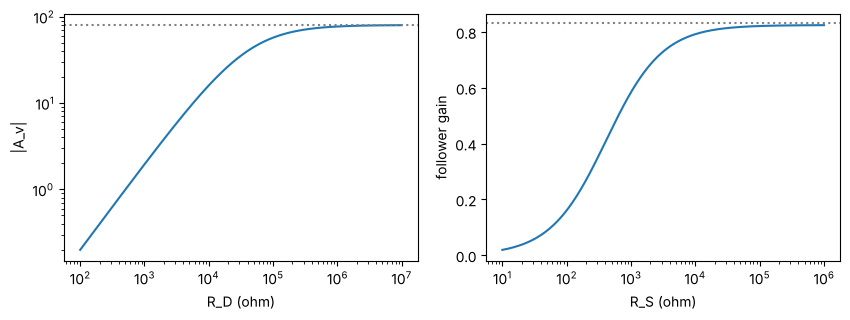

In [2]:
a_rd = cs_gain(RO); a_f = follower_gain(2e3)
print(f"CS gain at R_D = r_o: {a_rd:.3f};  follower gain at R_S = 2 kOhm: {a_f:.4f}")
assert abs(a_rd + 40) < 1e-9 and abs(a_f - 0.6838) < 5e-5
rd = np.logspace(2, 7, 300); rs = np.logspace(1, 6, 300)
fig, (a, b) = plt.subplots(1, 2, figsize=(8.6, 3.3))
a.loglog(rd, [abs(cs_gain(r)) for r in rd]); a.axhline(GM * RO, ls=":", color="0.5"); a.set_xlabel("R_D (ohm)"); a.set_ylabel("|A_v|")
b.semilogx(rs, [follower_gain(r) for r in rs]); b.axhline(1 / (1 + CHI), ls=":", color="0.5"); b.set_xlabel("R_S (ohm)"); b.set_ylabel("follower gain")
fig.tight_layout(); plt.show()

## Part 2 · Degeneration and distortion (guided exercise)

Example 10-06.1's transistor ($k_n$ = 4 mA/V², $V_{TN}$ = 0.5 V, $V_{ov}$ = 0.5 V, 0.5 mA), with and without $R_S$ = 500 Ω, the gate bias raised by $I_DR_S$ so the current is unchanged. *Predict first:* $\text{HD}_2$ at 50 mV for each.

R_S =     0 ohm, 50 mV: HD2 = 2.5000%, HD3 = 0.00000%
R_S =   500 ohm, 50 mV: HD2 = 0.6256%, HD3 = 0.00783%
100 mV: HD2 without R_S = 5.0000%, HD3 with R_S = 0.03145%


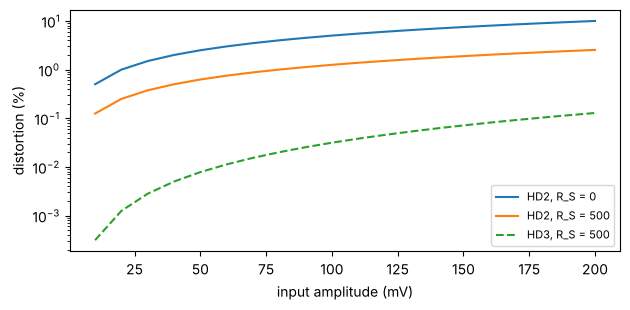

In [3]:
K, VTN, N = 4e-3, 0.5, 2048
theta = 2 * np.pi * np.arange(N) / N

def harmonics(amp, rs, vov=0.5, i0=0.5e-3):
    vg0 = VTN + vov + i0 * rs
    i = np.array([brentq(lambda x: x - 0.5 * K * max(vg0 + amp * math.cos(t) - x * rs - VTN, 0.0) ** 2, 0, 1)
                  for t in theta])
    c = np.fft.rfft(i) / N
    return abs(c[2]) / abs(c[1]) * 100, abs(c[3]) / abs(c[1]) * 100

for rs in (0.0, 500.0):
    h2, h3 = harmonics(0.05, rs)
    print(f"R_S = {rs:5.0f} ohm, 50 mV: HD2 = {h2:.4f}%, HD3 = {h3:.5f}%")
h2_0, _ = harmonics(0.1, 0.0); _, h3_d = harmonics(0.1, 500.0)
print(f"100 mV: HD2 without R_S = {h2_0:.4f}%, HD3 with R_S = {h3_d:.5f}%")
assert abs(h2_0 - 5.0) < 0.05 and abs(h3_d - 0.0315) < 5e-5
amps = np.linspace(0.01, 0.2, 20)
plt.figure(figsize=(6.4, 3.2))
for rs in (0.0, 500.0):
    plt.semilogy(amps * 1e3, [harmonics(a, rs)[0] for a in amps], label=f"HD2, R_S = {rs:.0f}")
plt.semilogy(amps * 1e3, [harmonics(a, 500.0)[1] for a in amps], "--", label="HD3, R_S = 500")
plt.xlabel("input amplitude (mV)"); plt.ylabel("distortion (%)"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## Part 3 · Gain and headroom

$|A_v| = g_mR_D$ with $g_m = 2I_D/V_{ov}$ and $R_D = V_{RD}/I_D$.

In [4]:
VRD = 2.5
def cs_from_bias(i_d, vov):
    gm = 2 * i_d / vov
    return abs(cs_gain(VRD / i_d, gm=gm, ro=1e30))
g_v = [cs_from_bias(0.5e-3, v) for v in (0.1, 0.2, 0.5)]
g_i = [cs_from_bias(i, 0.5) for i in (0.1e-3, 0.5e-3, 2e-3)]
print("gain vs V_ov at 0.5 mA:", [round(x, 3) for x in g_v])
print("gain vs current at V_ov = 0.5 V:", [round(x, 3) for x in g_i])
assert abs(g_v[1] - 25) < 1e-9 and max(g_i) - min(g_i) < 1e-9

gain vs V_ov at 0.5 mA: [np.float64(50.0), np.float64(25.0), np.float64(10.0)]
gain vs current at V_ov = 0.5 V: [np.float64(10.0), np.float64(10.0), np.float64(10.0)]


## Part 4 · Common-gate input resistance against the drain load

R_in = 1 kOhm at R_D = 57.000 kOhm; R_in at R_D = 0+: 412.4 ohm


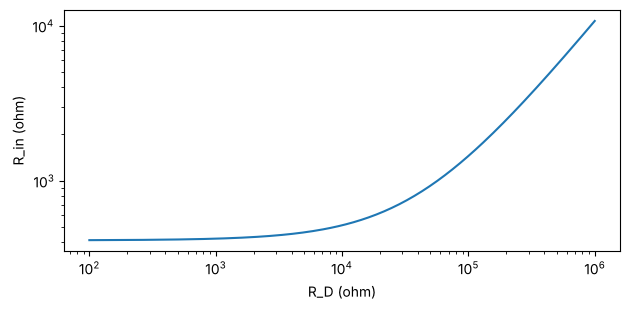

In [5]:
loads = np.logspace(2, 6, 200)
rin = np.array([cg_rin(r) for r in loads])
r_1k = brentq(lambda r: cg_rin(r) - 1e3, 1, 1e6)
print(f"R_in = 1 kOhm at R_D = {r_1k/1e3:.3f} kOhm; R_in at R_D = 0+: {cg_rin(1e-3):.1f} ohm")
assert abs(r_1k / 1e3 - 57) < 5e-3
plt.figure(figsize=(6.4, 3.2)); plt.loglog(loads, rin); plt.xlabel("R_D (ohm)"); plt.ylabel("R_in (ohm)")
plt.tight_layout(); plt.show()